# Objectif 
L'objectif est d'analyser les conditions de propagation permettant d'expliquer la propagation observée à l'OBS 7 au cours de la portion 1. 

Date de création : 14/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [3]:
portion_id = 1
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB ...
│   │           tir_src_lat            (src_datetime) float64 3kB ...
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB ...
│   │           tir_src_lat            (src_datetime) float64 2kB ...
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

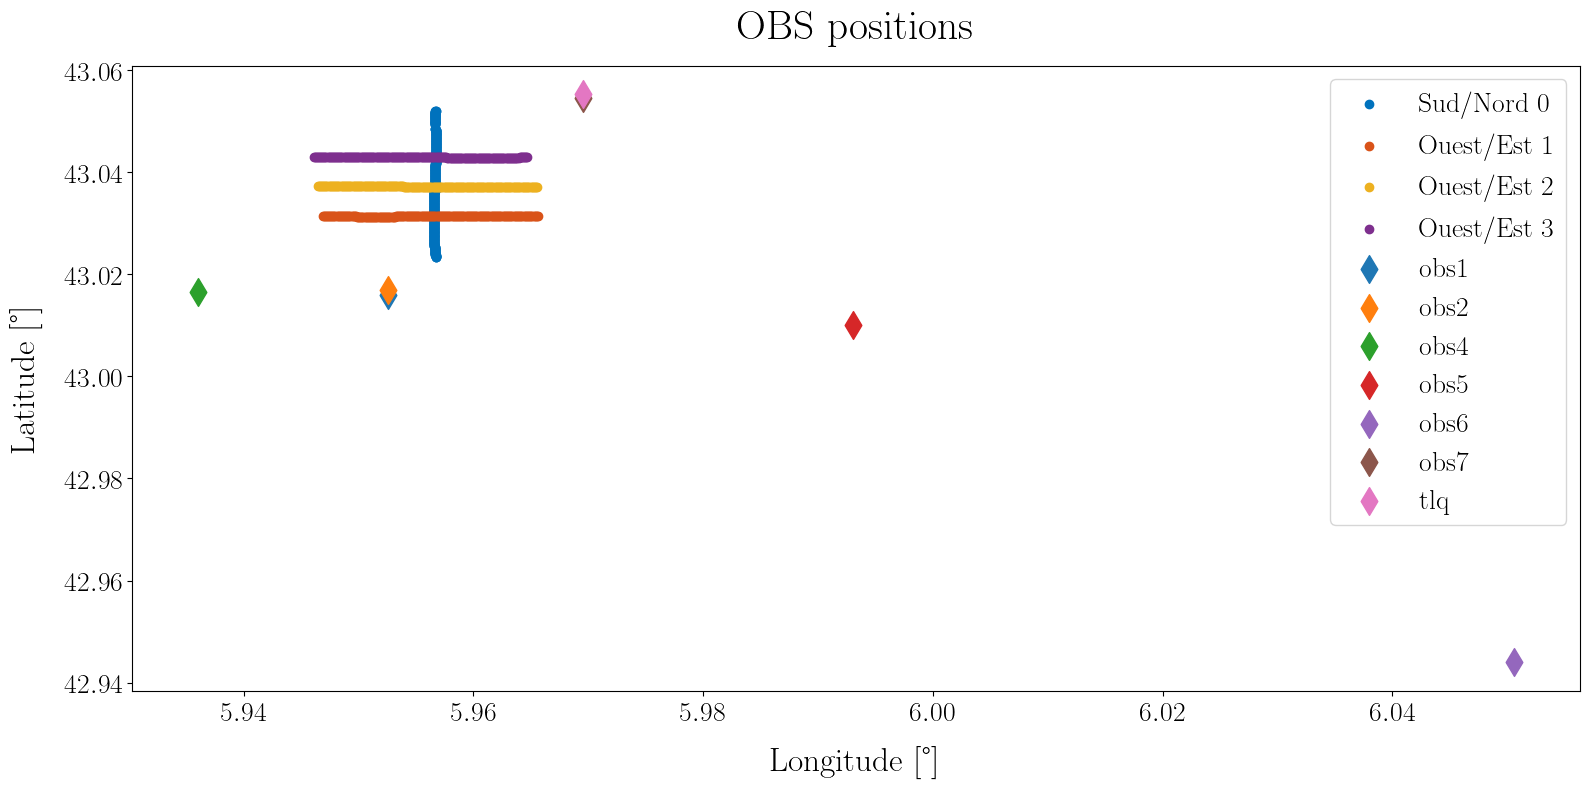

In [4]:
plot_portion_tir_pos(portion_tree=portion)

# Signaux d'intérêt 

Tracer des signaux étudiés. 

In [5]:
c0 = 1508       # equivalent celerity 
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

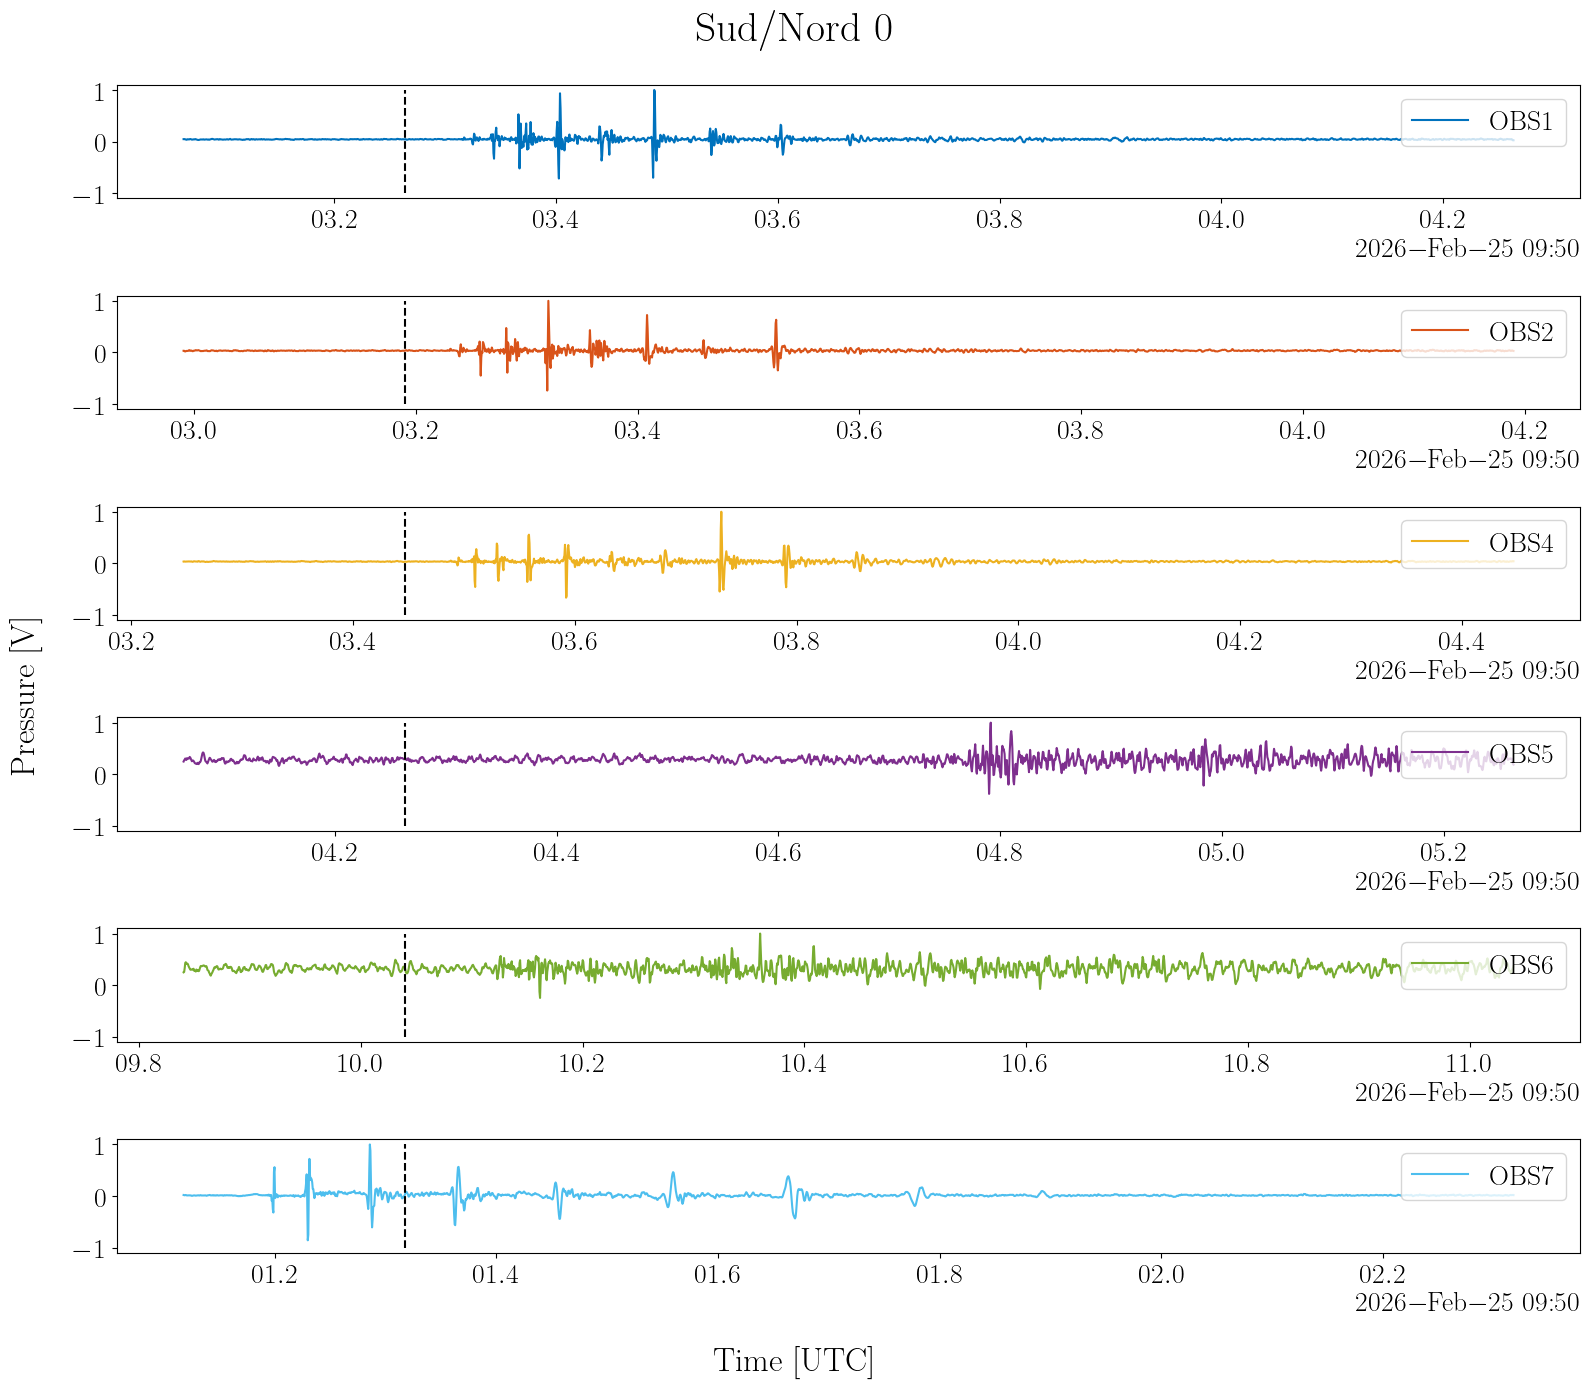

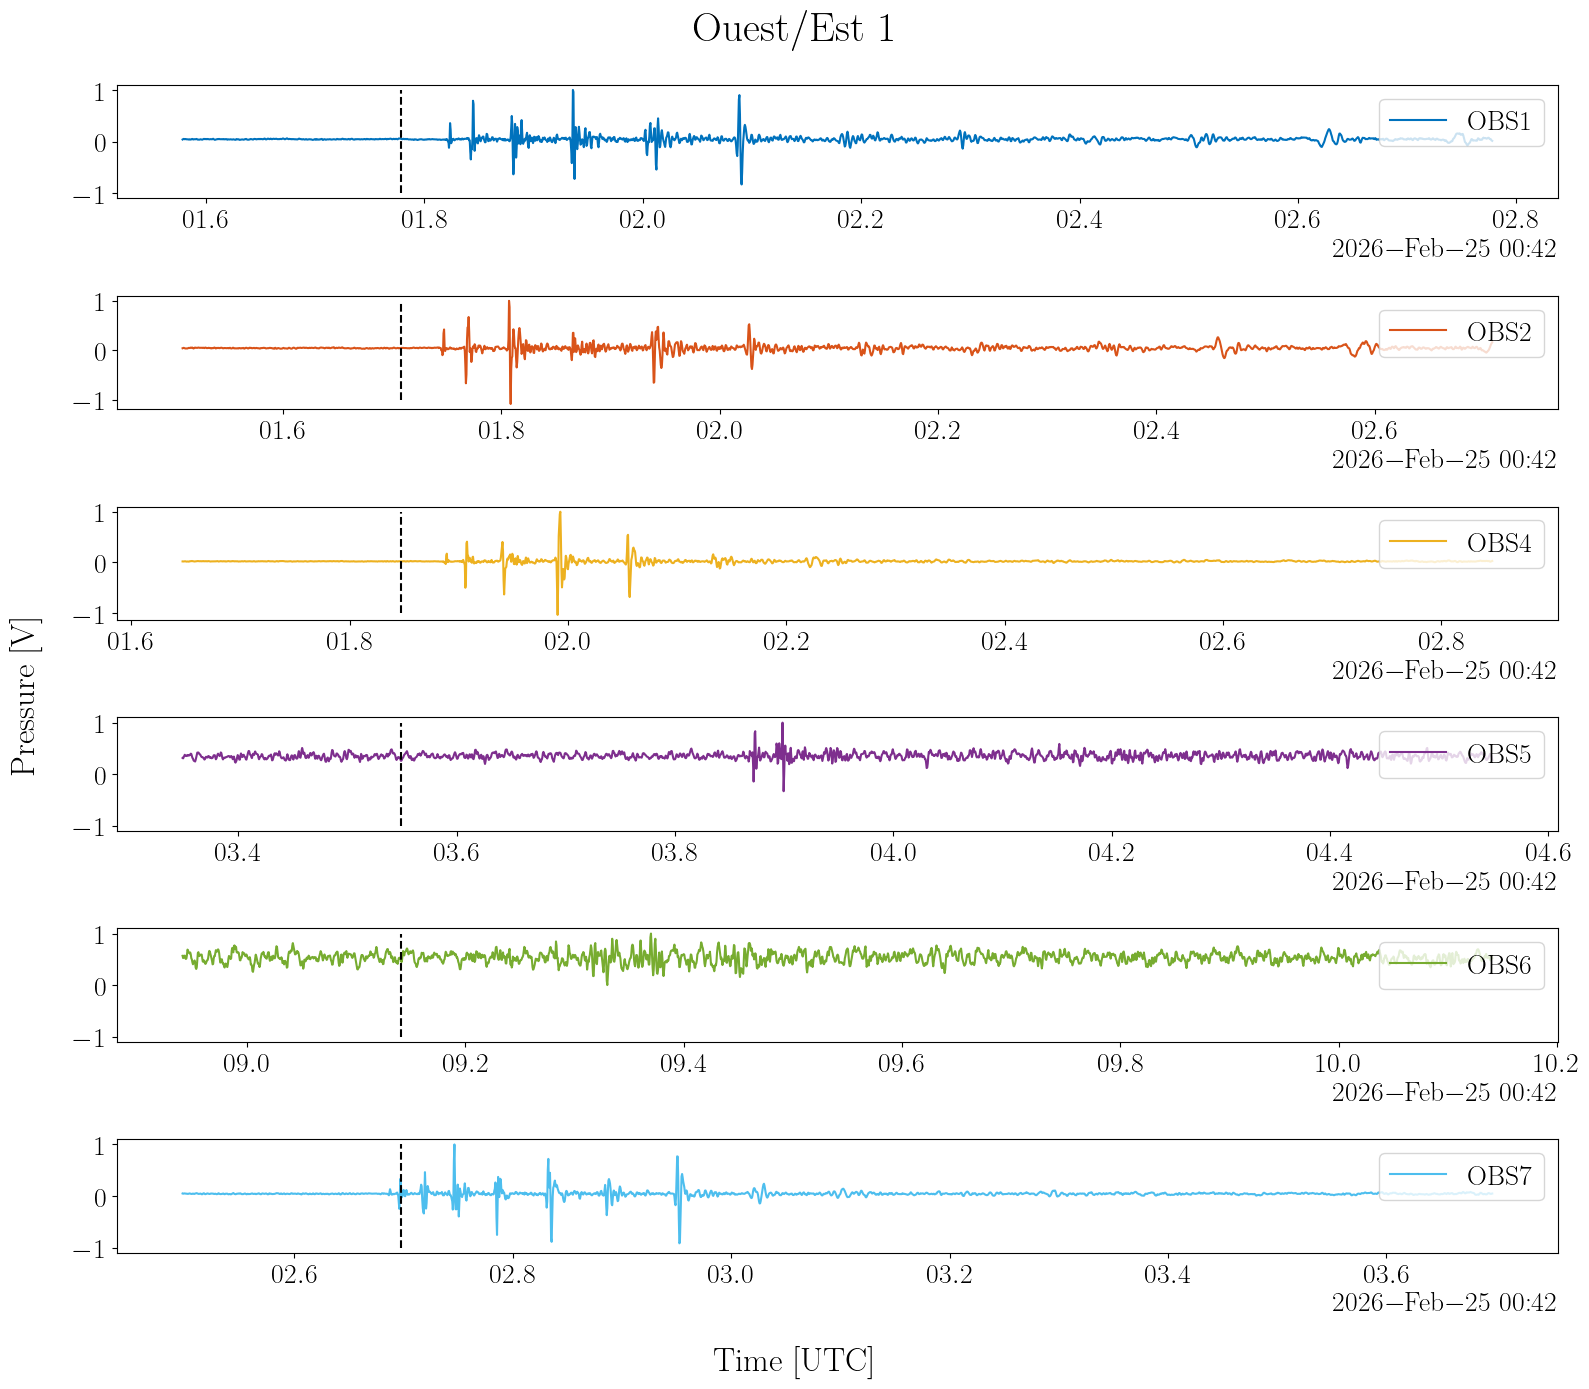

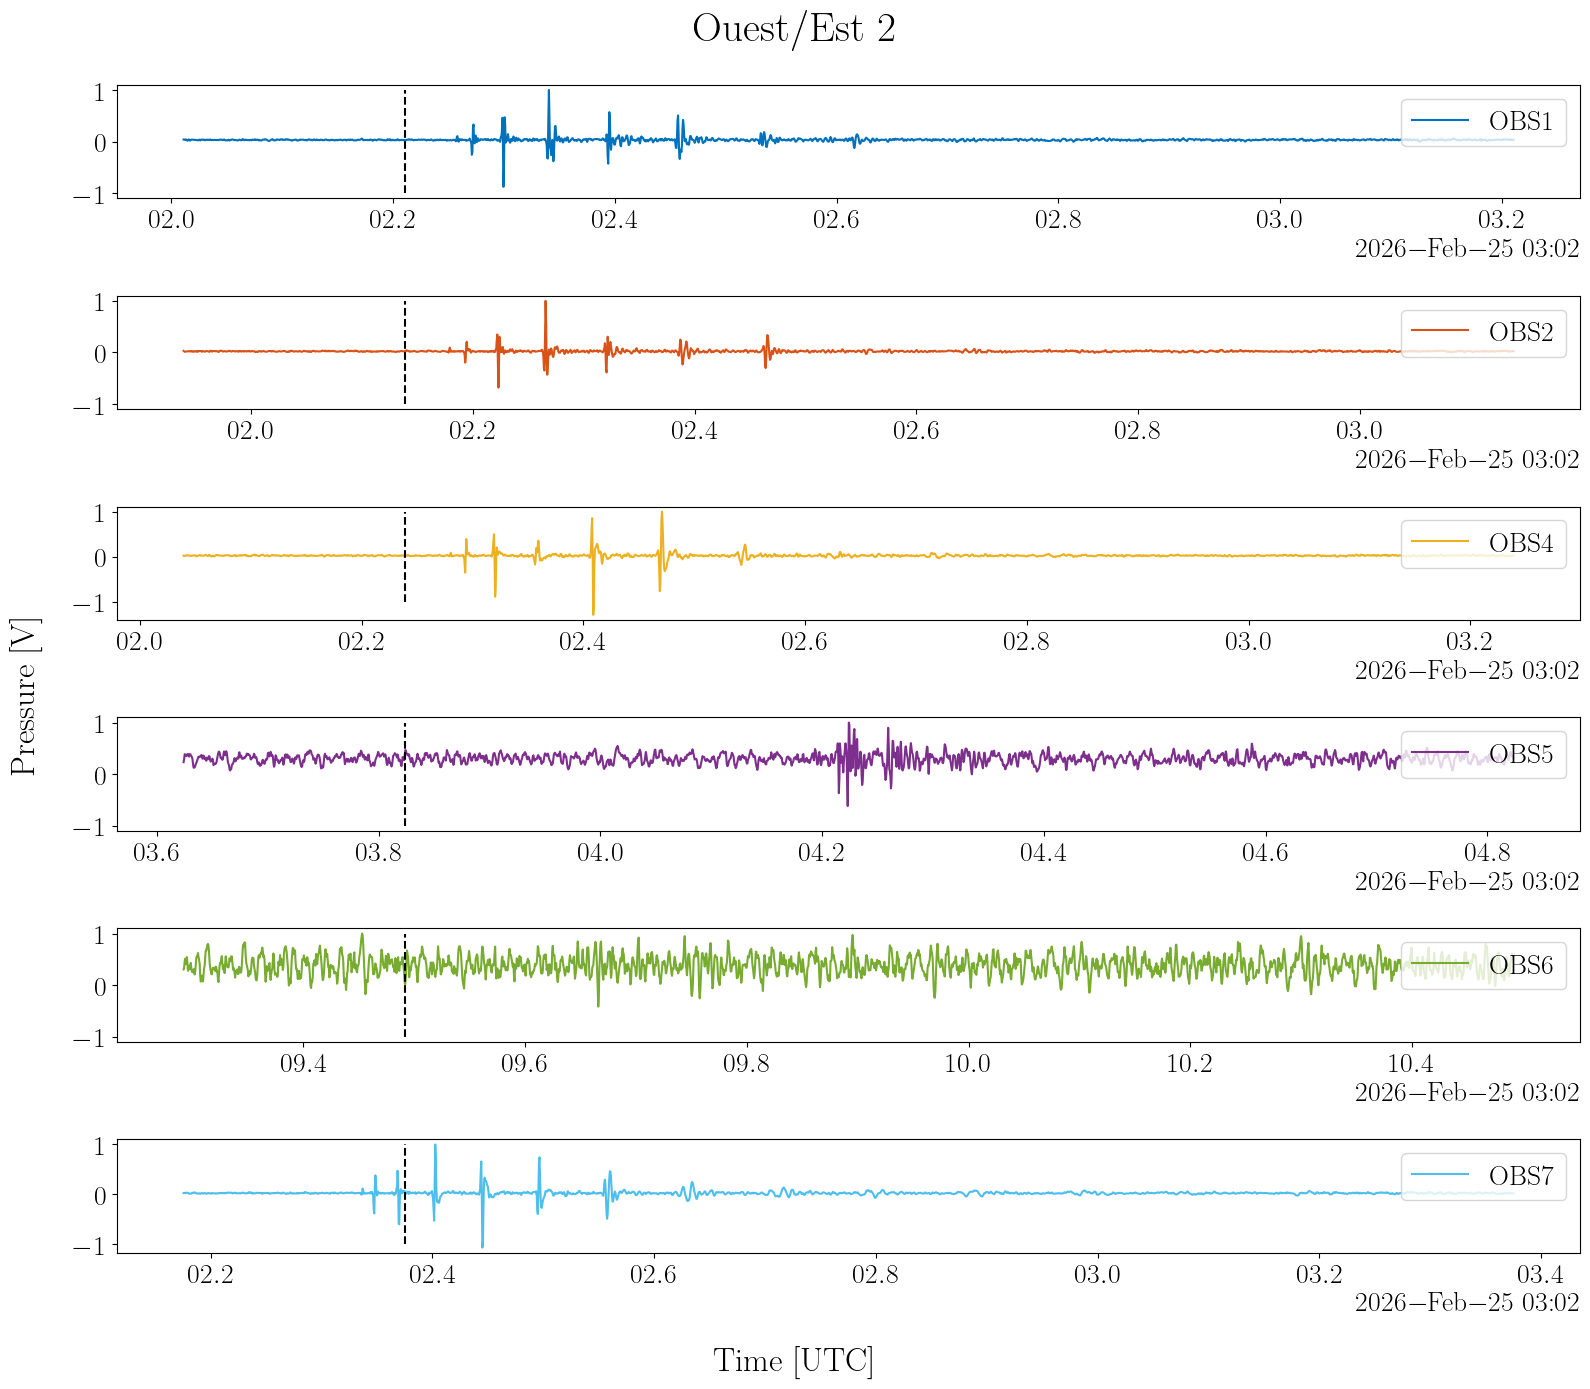

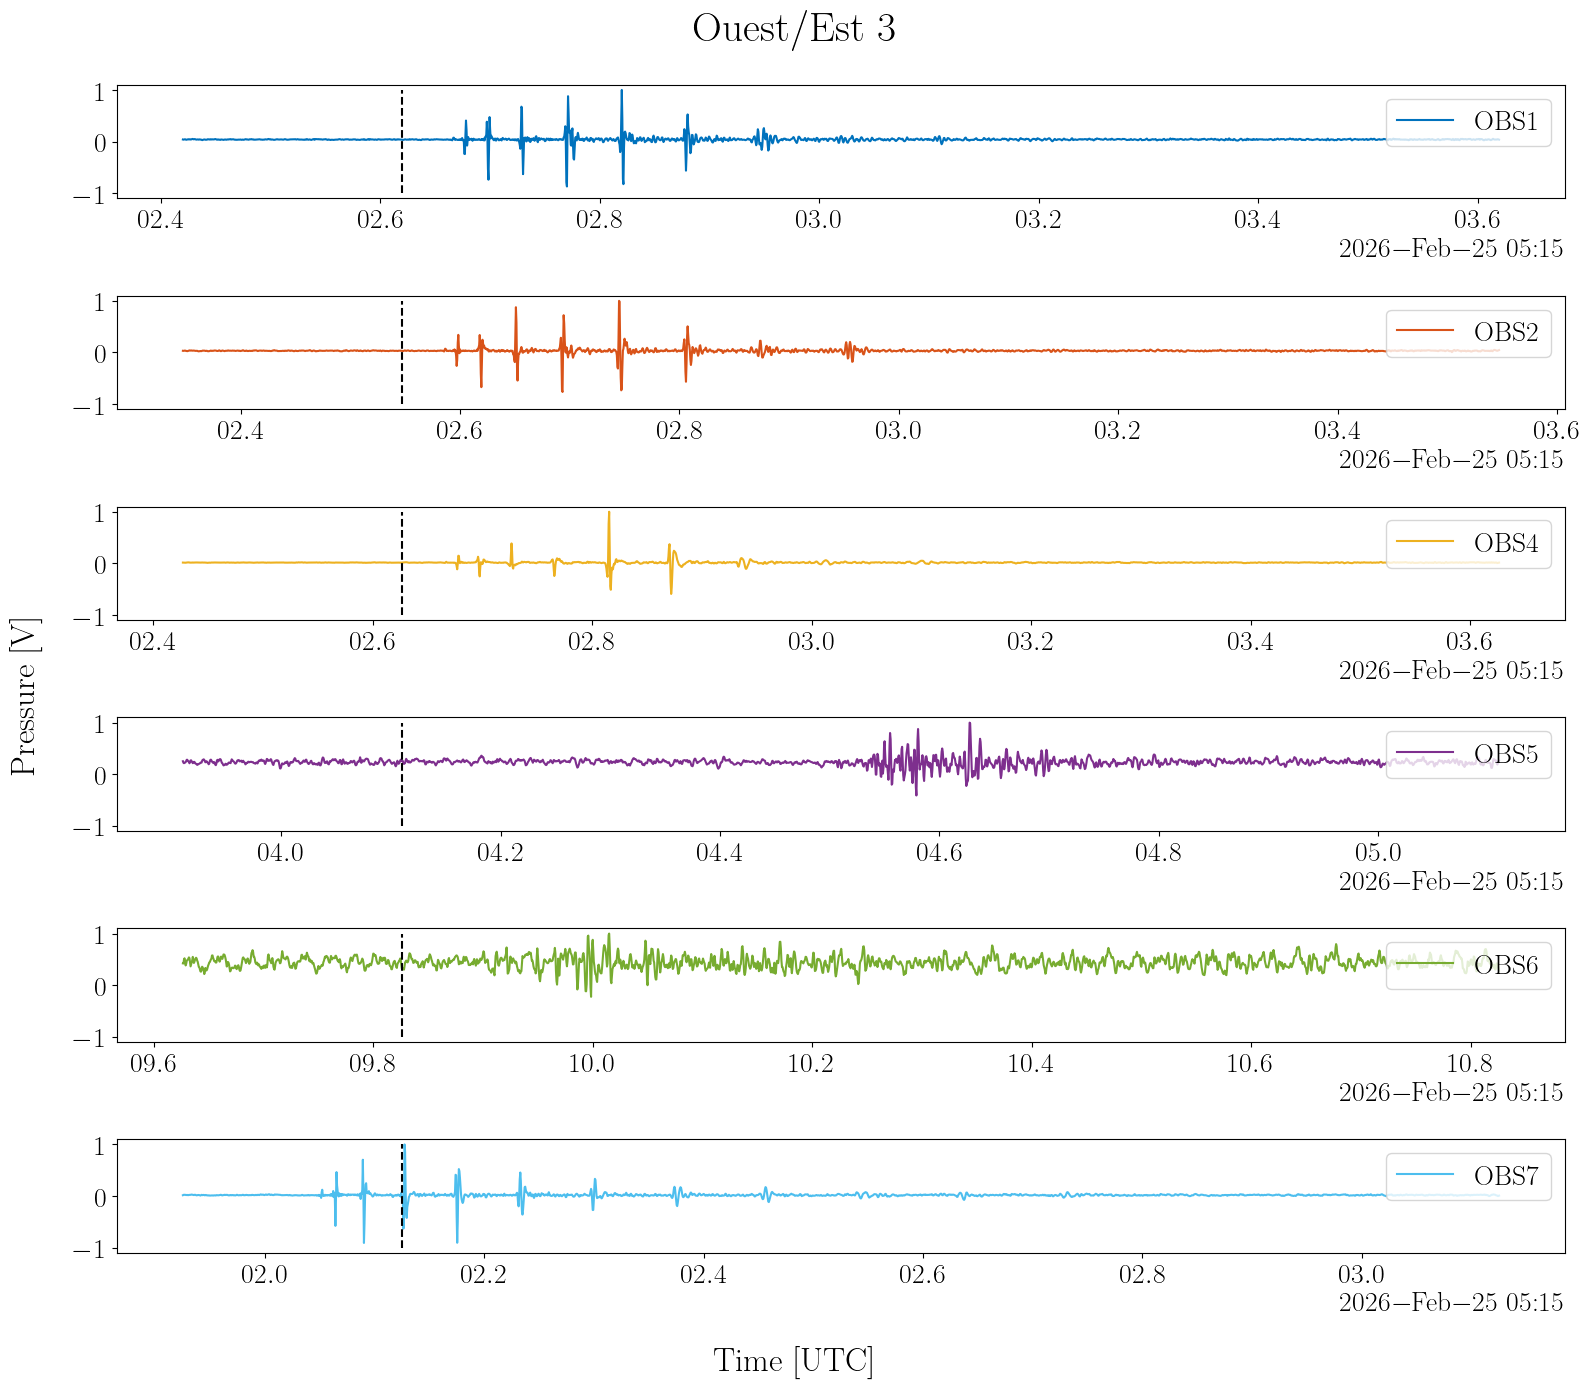

In [6]:
nb_tir = 1
offset1 = 200
offset2 = 1000
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 3, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

## Séléction d'une émission 


Text(0.02, 0.5, 'Pressure [V]')

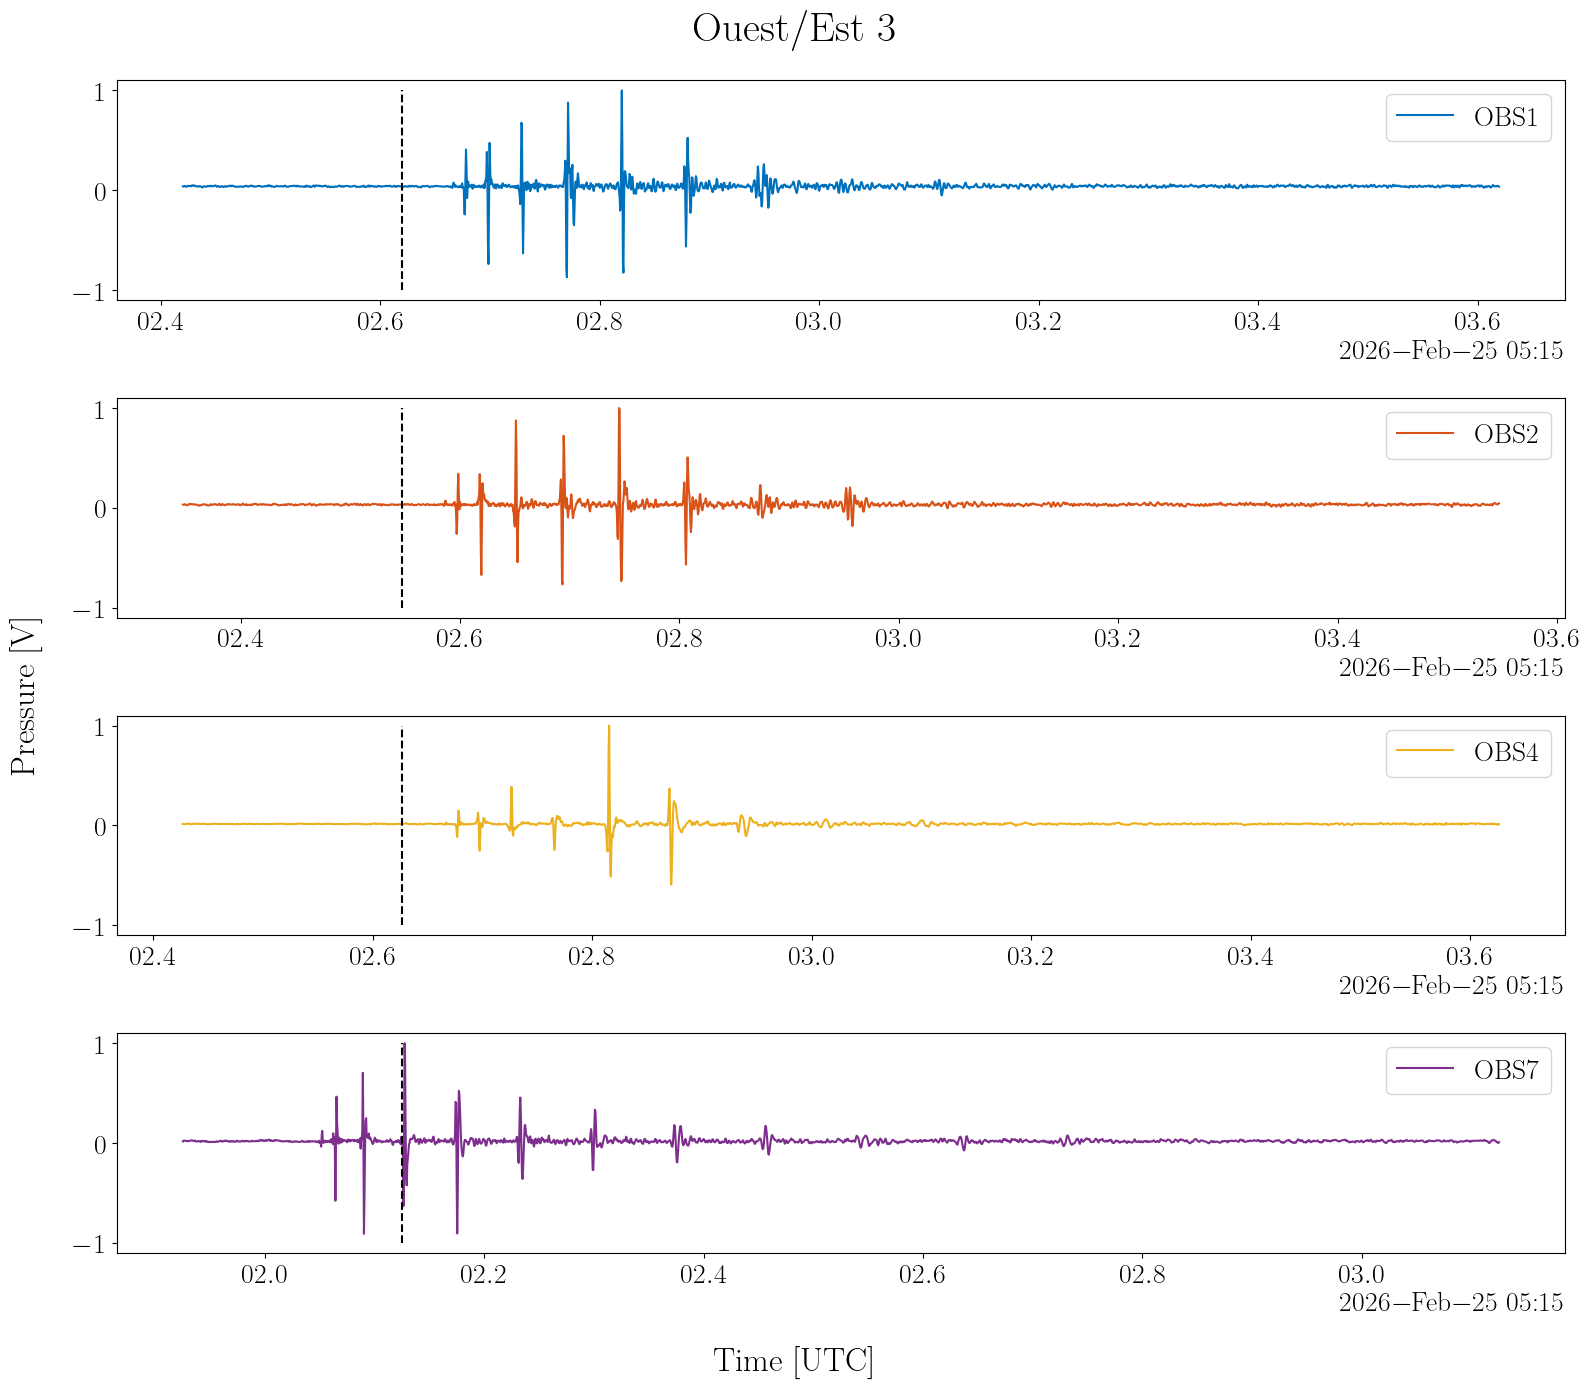

In [7]:
nb_tir = 1
offset1 = 200
offset2 = 1000

# Select OBS 1, 2, 4, and 7
obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
obs_ids = obs_ids[[0, 1, 2, 5]]
ds_pos_section = portion.position["oe3"].to_dataset()
ds_pos_section = ds_pos_section.isel(src_datetime=slice(0, 0 + nb_tir))
ds_pressure_section = portion.pressure["oe3"].to_dataset()

tir_dt = ds_pos_section["tir_reception_datetime"]
fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)
axs = axs.flatten()
for i, rcv_id in enumerate(obs_ids):
    tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
    # Select associated data window
    press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel(
        {
            f"time_{rcv_id}": slice(
                tir_dt_rcv.values[0] - np.timedelta64(offset1, "ms"),
                tir_dt_rcv.values[-1] + np.timedelta64(offset2, "ms"),
            )
        }
    )
    # Plot pressure signal
    # Normalize
    press_rcv = press_rcv / press_rcv.max()
    press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
    # Plot arrivals time
    axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
    # Add legend
    axs[i].legend(loc="upper right")

xlab = axs[0].get_xlabel()
ylab = axs[0].get_ylabel()

for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")

fig.suptitle(
    f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
)
fig.supxlabel(xlab)
fig.supylabel(ylab)

# Bathymétrie dans la zone 

In [8]:
ds_bathy = xr.open_dataset(ACOUPLANE_BATHY_NC_FPATH)

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


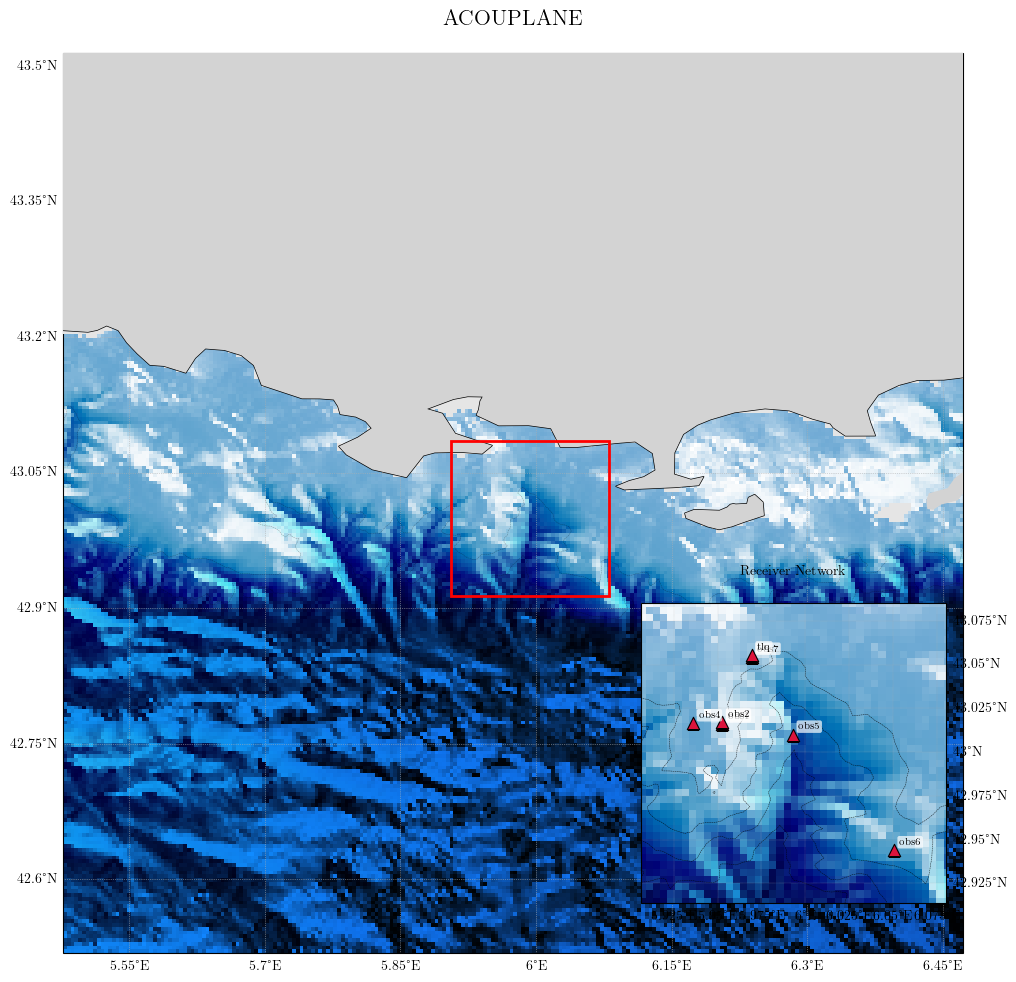

In [9]:
import numpy as np
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import LightSource
from matplotlib.patches import Rectangle

# # =============================================================================
# # INPUT DATA
# # =============================================================================

# Extract data
z = ds_bathy["elevation"].values
lon = ds_bathy["lon"].values
lat = ds_bathy["lat"].values

# # Receiver dataset
# rx_lon = np.array([obs4_lon, obs7_lon])
# rx_lat = np.array([obs7_lat, obs7_lat])
# rx_id = [4, 7]

# Receiver dataset
rx_lon = ds_pos_section.rcv_lon.values
rx_lat = ds_pos_section.rcv_lat.values
# rx_id = [int(obs_id[-1]) for obs_id in ds_pos_section.rcv_id.values]
rx_id = ds_pos_section.rcv_id.values

# =============================================================================
# DEFINE ZOOM AREA FROM RECEIVER NETWORK
# =============================================================================

pad = 0.03  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

# =============================================================================
# HILLSHADE
# =============================================================================

ls = LightSource(
    azdeg=315,
    altdeg=45,
)

# Hillshade computed on bathymetry
rgb = ls.shade(
    -z,  # invert bathymetry for proper relief
    cmap=plt.cm.Blues,
    vert_exag=8,
    blend_mode="overlay",
)


# =============================================================================
# FIGURE
# =============================================================================

fig = plt.figure(figsize=(14, 10))

# -----------------------------------------------------------------------------
# MAIN MAP
# -----------------------------------------------------------------------------

ax = fig.add_axes(
    [0.05, 0.05, 0.90, 0.90],
    projection=ccrs.PlateCarree(),
)

ax.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Bathymetric contours
levels = np.arange(
    np.floor(z.min() / 100) * 100,
    0,
    1000,
)

cs = ax.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.3,
    alpha=0.4,
    transform=ccrs.PlateCarree(),
)


# Zoom rectangle
rect = Rectangle(
    (zoom_extent[0], zoom_extent[2]),
    zoom_extent[1] - zoom_extent[0],
    zoom_extent[3] - zoom_extent[2],
    fill=False,
    edgecolor="red",
    linewidth=2,
    transform=ccrs.PlateCarree(),
    zorder=20,
)

ax.add_patch(rect)

# Grid
gl = ax.gridlines(
    draw_labels=True,
    linestyle=":",
    linewidth=0.5,
)

gl.top_labels = False
gl.right_labels = False

ax.set_title(
    # "Bathymetry and Receiver Network",
    "ACOUPLANE",
    fontsize=16,
)


# Create mask
land_mask = z >= 0

# Land color (RGB)
land_color = np.array([0.9, 0.9, 0.9])

# Replace land pixels by a uniform color
rgb_land = rgb.copy()
rgb_land[land_mask, :3] = land_color
rgb_land[~land_mask] = np.nan


ax.imshow(
    rgb_land,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
    zorder=16,
)

# Coastlines and land
ax.coastlines(resolution="10m", linewidth=1, zorder=17)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=17)

# =============================================================================
# INSET MAP
# =============================================================================

axins = fig.add_axes(
    [0.55, 0.10, 0.30, 0.30],  # left, bottom, width, height
    projection=ccrs.PlateCarree(),
)

# Bathymetry in inset
axins.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Bathymetric contours
levels = np.arange(
    np.floor(z.min() / 100) * 100,
    0,
    500,
)

# Contours
cs = axins.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.3,
    alpha=1,
    transform=ccrs.PlateCarree(),
)


# Receivers
axins.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=40,
)

# Receiver labels
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    axins.annotate(
        str(rid),
        (x, y),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="none",
            alpha=0.7,
        ),
        zorder=41,
    )

# Zoom extent
axins.set_extent(zoom_extent)

# Grid
gl2 = axins.gridlines(
    draw_labels=True,
    linestyle=":",
    linewidth=0.3,
)

gl2.top_labels = False
gl2.right_labels = True
gl2.left_labels = False

axins.set_title(
    "Receiver Network",
    fontsize=10,
)


plt.show()

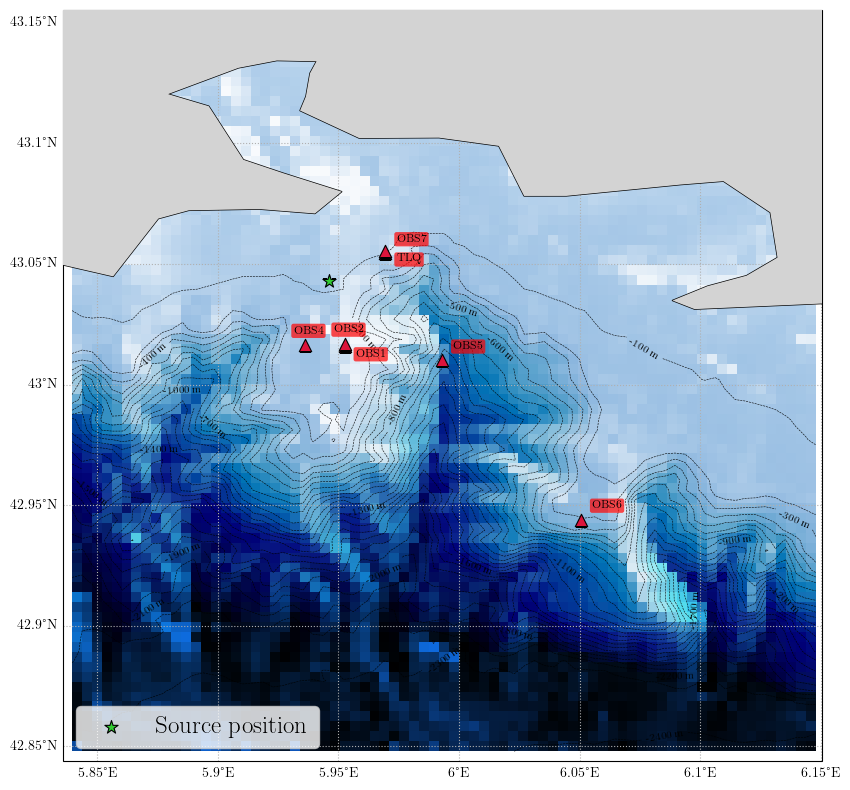

In [10]:
# Plot source position for selected ranges
pad = 0.1  # degrees

zoom_extent = [
    rx_lon.min() - pad,
    rx_lon.max() + pad,
    rx_lat.min() - pad,
    rx_lat.max() + pad,
]

bathy_zoom = ds_bathy.sel(
    lon=slice(zoom_extent[0], zoom_extent[1]), lat=slice(zoom_extent[2], zoom_extent[3])
)


z = bathy_zoom["elevation"].values
lon = bathy_zoom["lon"].values
lat = bathy_zoom["lat"].values

# Hillshade
ls = LightSource(azdeg=315, altdeg=45)  # illumination azimuth  # illumination elevation
rgb = ls.shade(-z, cmap=plt.cm.Blues, vert_exag=5, blend_mode="overlay")

# Figure
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())


# Shaded bathymetry
ax.imshow(
    rgb,
    origin="lower",
    extent=[lon.min(), lon.max(), lat.min(), lat.max()],
    transform=ccrs.PlateCarree(),
)

# Optional depth contours
levels = np.arange(np.floor(z.min() / 100) * 100, 0, 100)

cs = ax.contour(
    lon,
    lat,
    z,
    levels=levels,
    colors="k",
    linewidths=0.4,
    alpha=1,
    transform=ccrs.PlateCarree(),
)

ax.clabel(cs, fmt="%d m", fontsize=7)

# Coastlines and land
ax.coastlines(resolution="10m", linewidth=1, zorder=17)
ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=17)

# Grid
gl = ax.gridlines(draw_labels=True, linestyle=":")
gl.top_labels = False
gl.right_labels = False

ax.set_title("")

# Receivers
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)

# Receiver labels
i = 0
sign_x = [1, -1, -1, 1, 1, 1, 1, -1]
sign_y = [-1, 1, 1, 1, 1, 1, -1, 1]
for rid, x, y in zip(rx_id, rx_lon, rx_lat):
    ax.annotate(
        str(rid).upper(),
        (x, y),
        xytext=(sign_x[i]*8, sign_y[i]*8),
        textcoords="offset points",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="red",
            ec="none",
            alpha=0.7,
        ),
        zorder=11,
    )
    i += 1

# Add source position
ax.scatter(
    ds_pos_section.tir_src_lon,
    ds_pos_section.tir_src_lat,
    s=100,
    c="limegreen",
    marker="*",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
    label="Source position"
)


# Zoom on the area of interest
ax.set_extent(zoom_extent)

ax.legend(fontsize=18, loc="lower left")

# Modélisation de la propagation 

## Extraction des profils de bathymétrie 

In [11]:
from get_data.bathymetry.bathy_profile_extraction import extract_bathy_profile

In [12]:
# We need to rename elevation into bathymetry to use the functionbelow
xr_bathy = ds_bathy.rename(elevation="bathymetry")
xr_bathy

<xarray.Dataset> Size: 119kB
Dimensions:     (lat: 240, lon: 240)
Coordinates:
  * lat         (lat) float64 2kB 42.52 42.52 42.53 42.53 ... 43.51 43.51 43.51
  * lon         (lon) float64 2kB 5.477 5.481 5.485 5.49 ... 6.465 6.469 6.473
Data variables:
    bathymetry  (lat, lon) int16 115kB -2304 -2305 -2307 -2309 ... 244 214 167
Attributes:
    description:     Bathymetry data from GEBCO 2026
    geodesic_frame:  WGS84

In [13]:
bathy_profiles = {}
for rcv_id in ds_pos_section.rcv_id.values:
    r_profile, z_profile = extract_bathy_profile(
        xr_bathy=xr_bathy,
        start_lon=ds_pos_section.tir_src_lon.values[0],
        start_lat=ds_pos_section.tir_src_lat.values[0],
        stop_lon=ds_pos_section.sel(rcv_id=rcv_id).rcv_lon.values,
        stop_lat=ds_pos_section.sel(rcv_id=rcv_id).rcv_lat.values,
        range_resolution=100
    )
    z_profile = z_profile * -1  # Convert bathymetry to depth
    bathy_profiles[rcv_id] = {
            "range_m": r_profile,
            "depth_m": z_profile
    }

In [14]:
ax.scatter(
    rx_lon,
    rx_lat,
    s=80,
    c="crimson",
    marker="^",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
)


# Add source position
ax.scatter(
    ds_pos_section.tir_src_lon,
    ds_pos_section.tir_src_lat,
    s=100,
    c="limegreen",
    marker="*",
    edgecolors="black",
    linewidths=0.8,
    transform=ccrs.PlateCarree(),
    zorder=10,
    label="Source position",
)

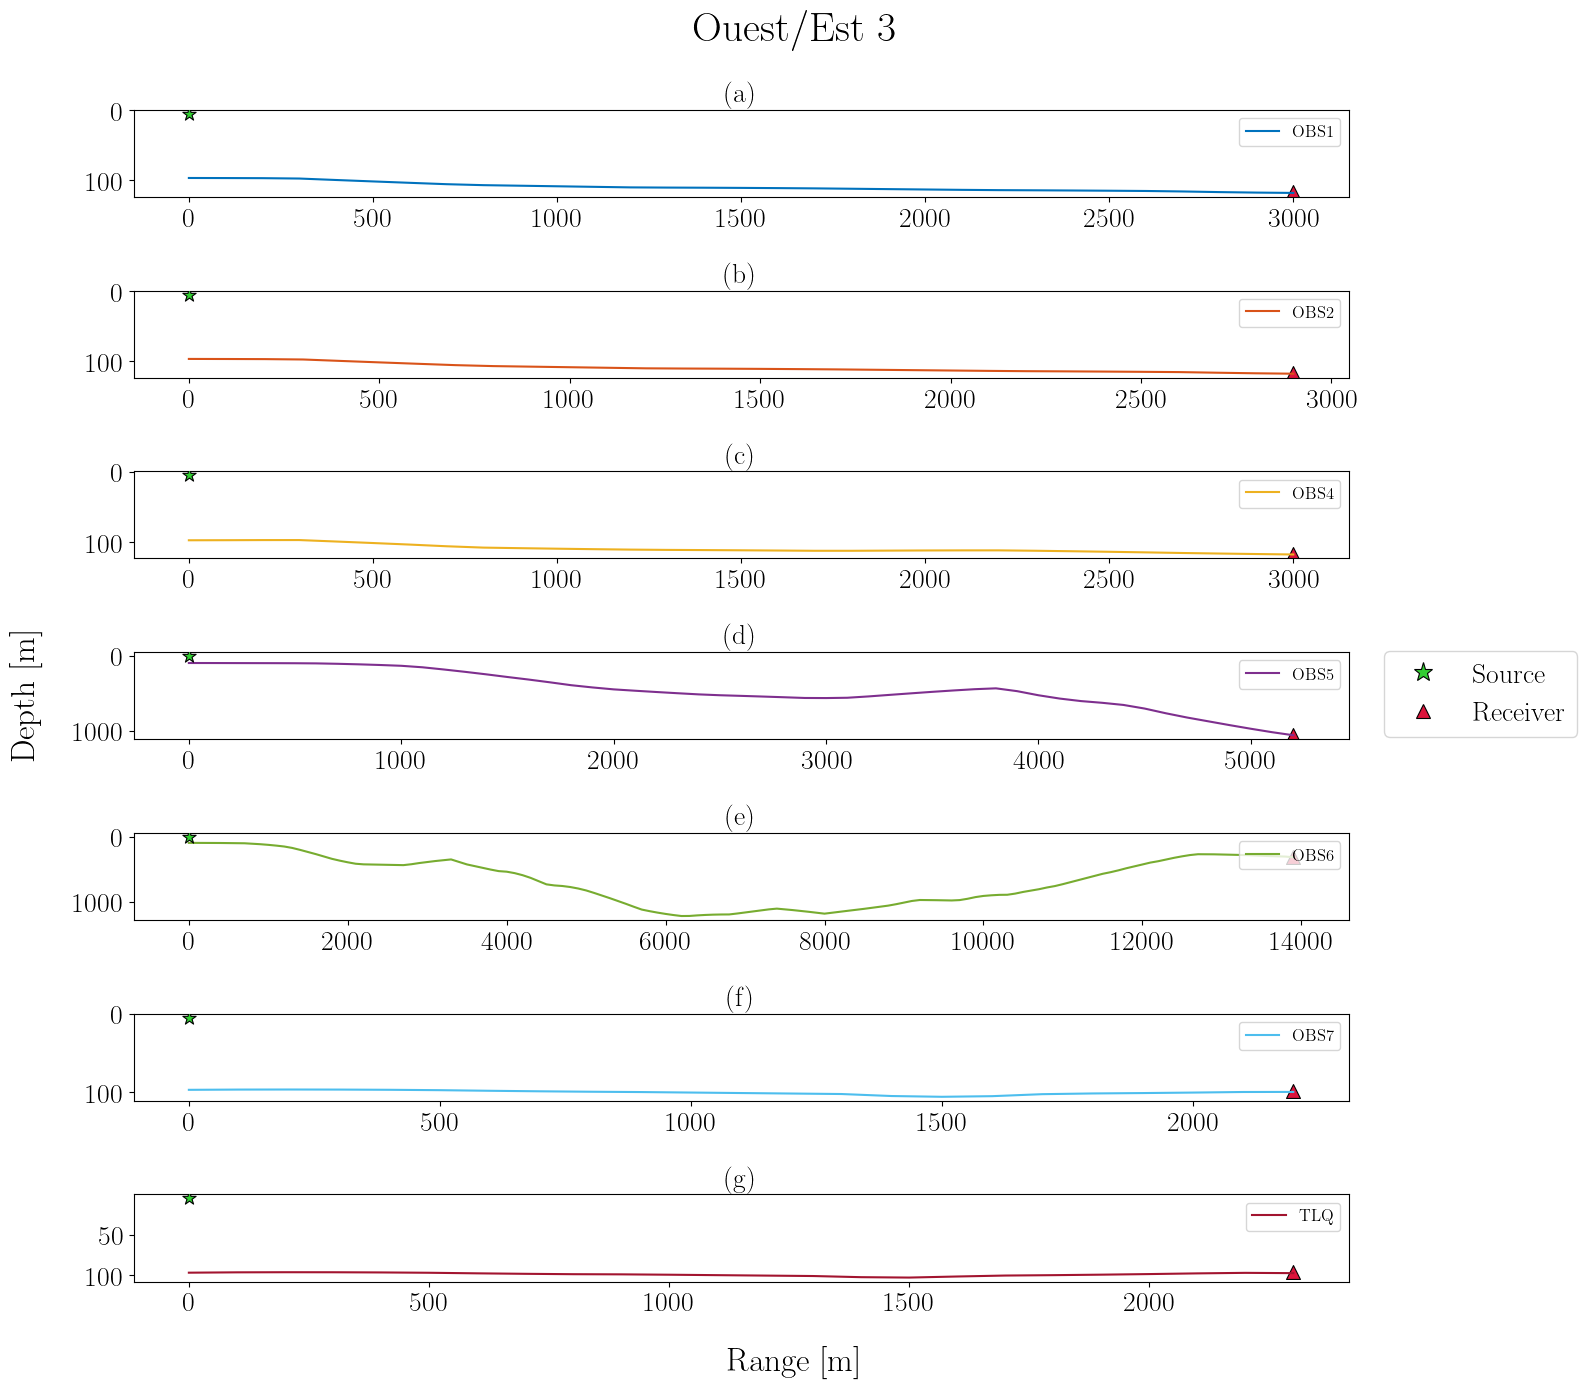

In [15]:
z_source = 5
fig, axs = plt.subplots(
    nrows=ds_pos_section.sizes["rcv_id"], ncols=1, figsize=(16, 14), sharex=False
)
axs = axs.flatten()
for i, rcv_id in enumerate(ds_pos_section.rcv_id.values):
    axs[i].plot(
        bathy_profiles[rcv_id]["range_m"],
        bathy_profiles[rcv_id]["depth_m"],
        label=rcv_id.upper(),
        color=color(i),
    )

    # Add source
    axs[i].scatter(
        bathy_profiles[rcv_id]["range_m"][0],
        z_source,
        s=100,
        c="limegreen",
        marker="*",
        edgecolors="black",
        linewidths=0.8,
        zorder=10,
        # label="Source",
    )
    # Add receiver
    axs[i].scatter(
        bathy_profiles[rcv_id]["range_m"][-1],
        bathy_profiles[rcv_id]["depth_m"][-1] - 1,
        s=100,
        c="crimson",
        marker="^",
        edgecolors="black",
        linewidths=0.8,
        # label="Receiver",
        # zorder=10,
    )

    # Add legend
    axs[i].legend(loc="upper right", fontsize=12)

for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title("")
    ax.invert_yaxis()

legend_handles = [
    Line2D(
        [0],
        [0],
        linestyle="None",
        marker="*",
        markersize=14,
        markerfacecolor="limegreen",
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="Source",
    ),
    Line2D(
        [0],
        [0],
        linestyle="None",
        marker="^",
        markersize=10,
        markerfacecolor="crimson",
        markeredgecolor="black",
        markeredgewidth=0.8,
        label="Receiver",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="outside right center",
    ncols=1,
    fontsize=20,
)

fig.suptitle(
    f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}"
)
fig.supxlabel("Range [m]")
fig.supylabel("Depth [m]")

set_subfigures_abc_labels(axs, x_pos=0.5, y_pos=1.02, fontsize=20, ha="center", va="bottom")

## Profil de célérité 

In [16]:
celerity = xr.open_datatree(ACOUPLANE_CELERITY_NC_FPATH)
celerity

<xarray.DataTree>
Group: /
├── Group: /T0_00006
│       Dimensions:      (depth: 322)
│       Coordinates:
│         * depth        (depth) float64 3kB 0.0 0.6301 1.26 1.89 ... 198.8 199.4 200.0
│       Data variables:
│           temperature  (depth) float64 3kB ...
│           celerity     (depth) float64 3kB ...
│       Attributes:
│           longitude:                 5.9519785
│           latitude:                  43.0480848
│           surface_temperatude_degC:  14.2
│           pression_atmo_hPa:         1021.0
│           salinity_ppt:              37.5
├── Group: /T0_00007
│       Dimensions:      (depth: 253)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 156.2 156.8 157.4
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 5.9523738
│           latitude:                  43.0173035
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1020.2
│           salinity_ppt:              37.5
├── Group: /T0_00012
│       Dimensions:      (depth: 160)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 98.39 99.02 99.64
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 5.9512852
│           latitude:                  43.0566788
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1025.6
│           salinity_ppt:              37.5
├── Group: /T0_00020
│       Dimensions:      (depth: 233)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 143.8 144.4 145.0
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 6.2931097
│           latitude:                  42.9943315
│           surface_temperatude_degC:  14.1
│           pression_atmo_hPa:         1027.3
│           salinity_ppt:              37.5
├── Group: /T0_00021
│       Dimensions:      (depth: 111)
│       Coordinates:
│         * depth        (depth) float64 888B 0.0 0.6301 1.26 1.89 ... 67.8 68.42 69.05
│       Data variables:
│           temperature  (depth) float64 888B ...
│           celerity     (depth) float64 888B ...
│       Attributes:
│           longitude:                 6.269442
│           latitude:                  43.0373697
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1026.7
│           salinity_ppt:              37.5
├── Group: /T0_00022
│       Dimensions:      (depth: 144)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 88.41 89.04 89.66
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 6.2833635
│           latitude:                  43.058786
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1026.9
│           salinity_ppt:              37.4
...
├── Group: /T7_00011
│       Dimensions:      (depth: 836)
│       Coordinates:
│         * depth        (depth) float64 7kB 0.0 0.6472 1.294 ... 524.1 524.7 525.4
│       Data variables:
│           temperature  (depth) float64 7kB ...
│           celerity     (depth) float64 7kB ...
│       Attributes:
│           longitude:                 5.9700047
│           latitude:                  43.0205393
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1023.7
│           salinity_ppt:              37.5
├── Group: /T7_00013
│       Dimensions:      (depth: 561)
│       Coordinates:
│         * depth        (depth) float64 4kB 0.0 0.6472 1.294 ... 354.4 355.0 355.7
│       

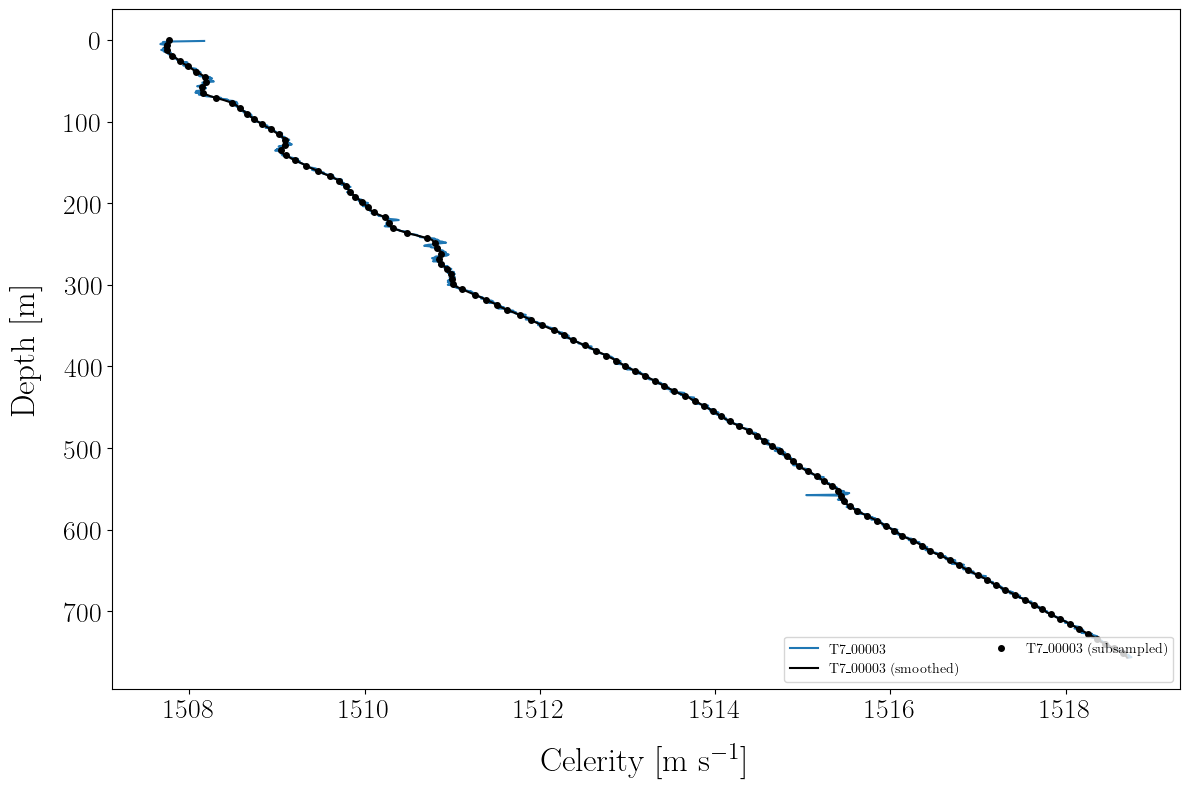

In [17]:
selected_profile = "T7_00003"
# selected_profile = "T0_00020"

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for name, node in celerity.children.items():
    if name == selected_profile:
        ds_celerity = node.to_dataset()
        ds_celerity.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)

        # Apply rolling mean
        smooth_celerity_profile = ds_celerity.celerity.rolling(
            depth=20, center=True, min_periods=1
        ).mean()
        smooth_celerity_profile.plot(y="depth", ax=ax, yincrease=False, label=f"{name} (smoothed)", color="k")

        # Use smooth profile
        z_ssp, cp_ssp = smooth_celerity_profile.depth.values, smooth_celerity_profile.values
        # Subsample profile
        z_ssp = z_ssp[::10]
        cp_ssp = cp_ssp[::10]
        ax.plot(cp_ssp, z_ssp, "o", color="k", markersize=4, label=f"{name} (subsampled)")

ax.legend(loc="lower right", ncols=2, fontsize=10)
# plt.ylim(20, 0)

## Calcul de la propa avec Kraken 

In [18]:
bathy_profiles

{np.str_('obs1'): {'range_m': array([   0,  100,  200,  300,  400,  500,  600,  700,  800,  900, 1000,
         1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100,
         2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900, 3000]),
  'depth_m': array([ 97.08931742,  97.1998154 ,  97.35404784,  97.88796101,
          99.97904709, 102.0263996 , 104.03002042, 105.98991137,
         107.38178661, 108.1812751 , 108.98076559, 109.78025807,
         110.57975255, 110.85846675, 111.04390916, 111.29493185,
         111.61153203, 112.00222847, 112.53042441, 113.05861765,
         113.58680819, 114.11499603, 114.52304272, 114.75887167,
         115.03840603, 115.36164394, 115.72858356, 116.42524442,
         117.34178696, 118.04286106, 118.52542171])},
 np.str_('obs2'): {'range_m': array([   0,  100,  200,  300,  400,  500,  600,  700,  800,  900, 1000,
         1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 1900, 2000, 2100,
         2200, 2300, 2400, 2500, 2600, 2700, 2800, 2900]),


In [19]:
# Use smooth profile 
z_ssp, cp_ssp = smooth_celerity_profile.depth.values, smooth_celerity_profile.values
# Subsample profile 
z_ssp = z_ssp[::10]
cp_ssp = cp_ssp[::10]

In [20]:
rbathy = bathy_profiles["obs1"]["range_m"]
zbathy = bathy_profiles["obs1"]["depth_m"]

In [21]:
from real_data_analysis.acouplane.src.analyse_portion.run_receivers_propagation import run_all_receivers

In [ ]:
run_all_receivers(
    bathy_profiles, z_ssp, cp_ssp, run_kraken=False
)  # d'abord : fichiers + figures d'environnement

In [22]:
# run_all_receivers(
#     bathy_profiles, z_ssp, cp_ssp, run_kraken=False
# )  # d'abord : fichiers + figures d'environnement
results, failed = run_all_receivers(
    bathy_profiles, z_ssp, cp_ssp, run_kraken=True, only=["obs1"], test_mode=True
)  # puis un test
# run_all_receivers(bathy_profiles, z_ssp, cp_ssp, run_kraken=True)


===== Receiver obs1 =====
Note: extending KrakenField's receiver depth range from 119.0 m to 300.0 m (the bottom of the buffer sediment layer) -- FIELD.exe requires receivers to reach that depth to compute the coupled-mode coupling coefficients.


C:\Users\baptiste.menetrier\Desktop\devPy\phd\propa\kraken_toolbox\plot_utils.py:1318: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


Running Kraken  (parallel = True)...
Broadband range dependent kraken simulation completed.
obs1: diagnostic figures at [100. 400. 800.] Hz

Done.


C:\Users\baptiste.menetrier\Desktop\devPy\phd\propa\kraken_toolbox\plot_utils.py:1125: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
